# Brain Tumor Segmentation using U-Net++ with ResNet34

## Additional Contributions

1. Image equalization using CLAHE
2. Gaussian noise removal
3. Gabor filtering
4. Binary tumor/no-tumor classification
5. Segmentation evaluation
6. Classification evaluation
7. Grad-CAM visualization
8. Grad-CAM vs ground-truth tumor-mask validation

Dataset: BraTS 2020
Framework: PyTorch
Segmentation: U-Net++
Encoder: ResNet34
Classification: ResNet18
Input Size: 128 × 128

In [1]:
!pip install -q segmentation-models-pytorch
!pip install -q grad-cam

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 1.5 MB/s eta 0:00:00a 0:00:01
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 634.4 kB/s eta 0:00:00 0:00:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import os
import random
import warnings
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import models
from torchvision import transforms

import segmentation_models_pytorch as smp

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve
)

warnings.filterwarnings("ignore")

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("SMP:", smp.__version__)

PyTorch: 2.10.0+cu128
Torchvision: 0.25.0+cu128
SMP: 0.5.0


In [3]:
SEED = 42

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


seed_everything(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU Memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / 1024**3,
            2
        ),
        "GB"
    )

Device: cuda
GPU: Tesla T4
GPU Memory: 14.56 GB


In [4]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets"):
    level = root.replace("/kaggle/input/datasets", "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:20]:
        print(f"{indent}    {file}")

datasets/
    dipakn/
        brain-tumor-by-tejas/
            brats2020-2d/
                val.csv
                train.csv
                images/
                    img_03638.tif
                    img_03748.tif
                    img_00886.tif
                    img_02352.tif
                    img_00333.tif
                    img_02756.tif
                    img_03089.tif
                    img_03874.tif
                    img_02705.tif
                    img_03049.tif
                    img_02376.tif
                    img_00424.tif
                    img_00069.tif
                    img_03693.tif
                    img_01364.tif
                    img_02458.tif
                    img_03452.tif
                    img_00169.tif
                    img_00582.tif
                    img_03611.tif
                masks/
                    mask_00947.tif
                    mask_03276.tif
                    mask_00605.tif
                    mask_01441.tif
     

In [5]:
DATASET_ROOT = Path("/kaggle/input/datasets/dipakn/brain-tumor-by-tejas/brats2020-2d")

TRAIN_CSV = DATASET_ROOT / "train.csv"
VAL_CSV = DATASET_ROOT / "val.csv"

IMAGE_DIR = DATASET_ROOT / "images"
MASK_DIR = DATASET_ROOT / "masks"

print("Dataset root:", DATASET_ROOT)
print("Train CSV:", TRAIN_CSV)
print("Val CSV:", VAL_CSV)
print("Image directory:", IMAGE_DIR)
print("Mask directory:", MASK_DIR)

Dataset root: /kaggle/input/datasets/dipakn/brain-tumor-by-tejas/brats2020-2d
Train CSV: /kaggle/input/datasets/dipakn/brain-tumor-by-tejas/brats2020-2d/train.csv
Val CSV: /kaggle/input/datasets/dipakn/brain-tumor-by-tejas/brats2020-2d/val.csv
Image directory: /kaggle/input/datasets/dipakn/brain-tumor-by-tejas/brats2020-2d/images
Mask directory: /kaggle/input/datasets/dipakn/brain-tumor-by-tejas/brats2020-2d/masks


In [6]:
print("Dataset root exists:", DATASET_ROOT.exists())
print("Train CSV exists:", TRAIN_CSV.exists())
print("Val CSV exists:", VAL_CSV.exists())
print("Image directory exists:", IMAGE_DIR.exists())
print("Mask directory exists:", MASK_DIR.exists())

if TRAIN_CSV.exists():
    train_df = pd.read_csv(TRAIN_CSV)
    print("\nTrain shape:", train_df.shape)
    display(train_df.head())

if VAL_CSV.exists():
    val_df = pd.read_csv(VAL_CSV)
    print("\nValidation shape:", val_df.shape)
    display(val_df.head())

Dataset root exists: True
Train CSV exists: True
Val CSV exists: True
Image directory exists: True
Mask directory exists: True

Train shape: (3143, 2)


,image,mask
0,img_02330.tif,mask_02330.tif
1,img_02638.tif,mask_02638.tif
2,img_03189.tif,mask_03189.tif
3,img_01922.tif,mask_01922.tif
4,img_03595.tif,mask_03595.tif



Validation shape: (786, 2)


,image,mask
0,img_01835.tif,mask_01835.tif
1,img_01490.tif,mask_01490.tif
2,img_02063.tif,mask_02063.tif
3,img_01178.tif,mask_01178.tif
4,img_03749.tif,mask_03749.tif


In [7]:
print("Train columns:")
print(train_df.columns.tolist())

print("\nValidation columns:")
print(val_df.columns.tolist())

Train columns:
['image', 'mask']

Validation columns:
['image', 'mask']


In [8]:
def clahe_equalization(image):
    """
    Apply CLAHE to grayscale MRI image.
    """

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    return clahe.apply(image)


def gaussian_noise_removal(image):
    """
    Remove high-frequency noise using Gaussian filtering.
    """

    return cv2.GaussianBlur(
        image,
        (5, 5),
        sigmaX=0
    )


def normalize_image(image):
    """
    Normalize image to [0, 1].
    """

    image = image.astype(np.float32)

    image -= image.min()

    max_value = image.max()

    if max_value > 0:
        image /= max_value

    return image


def preprocess_mri(image_path):

    image = cv2.imread(
        str(image_path),
        cv2.IMREAD_GRAYSCALE
    )

    if image is None:
        raise FileNotFoundError(
            f"Could not read image: {image_path}"
        )

    # Step 1: CLAHE
    image = clahe_equalization(image)

    # Step 2: Gaussian filtering
    image = gaussian_noise_removal(image)

    # Step 3: normalize
    image = normalize_image(image)

    return image

In [9]:
def create_gabor_kernels():

    kernels = []

    orientations = [
        0,
        np.pi / 4,
        np.pi / 2,
        3 * np.pi / 4
    ]

    for theta in orientations:

        kernel = cv2.getGaborKernel(
            ksize=(21, 21),
            sigma=5.0,
            theta=theta,
            lambd=10.0,
            gamma=0.5,
            psi=0,
            ktype=cv2.CV_32F
        )

        kernels.append(kernel)

    return kernels


GABOR_KERNELS = create_gabor_kernels()


def apply_gabor_filter(image):

    responses = []

    for kernel in GABOR_KERNELS:

        response = cv2.filter2D(
            image,
            cv2.CV_32F,
            kernel
        )

        responses.append(response)

    # Maximum response across orientations
    gabor = np.max(
        np.stack(responses),
        axis=0
    )

    gabor = cv2.normalize(
        gabor,
        None,
        0,
        1,
        cv2.NORM_MINMAX
    )

    return gabor.astype(np.float32)

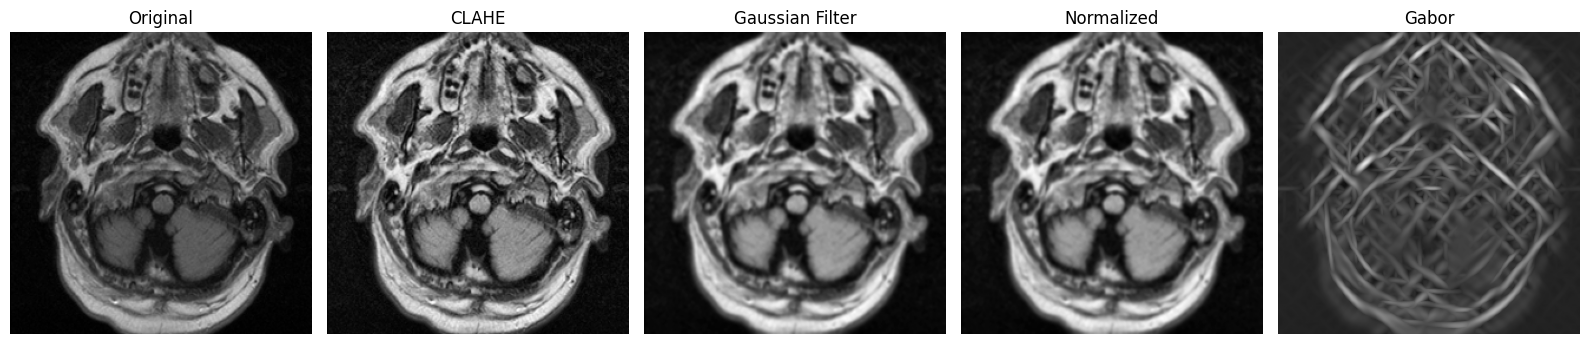

In [10]:
sample_row = train_df.iloc[0]

sample_image_path = IMAGE_DIR / sample_row["image"]

original = cv2.imread(
    str(sample_image_path),
    cv2.IMREAD_GRAYSCALE
)

clahe = clahe_equalization(original)

gaussian = gaussian_noise_removal(clahe)

normalized = normalize_image(gaussian)

gabor = apply_gabor_filter(normalized)


plt.figure(figsize=(16, 4))

plt.subplot(1, 5, 1)
plt.imshow(original, cmap="gray")
plt.title("Original")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(clahe, cmap="gray")
plt.title("CLAHE")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(gaussian, cmap="gray")
plt.title("Gaussian Filter")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(normalized, cmap="gray")
plt.title("Normalized")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(gabor, cmap="gray")
plt.title("Gabor")
plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
def create_three_channel_image(image_path):

    # Preprocessed MRI
    mri = preprocess_mri(image_path)

    # Gabor
    gabor = apply_gabor_filter(mri)

    # Sobel magnitude
    sobel_x = cv2.Sobel(
        mri,
        cv2.CV_32F,
        1,
        0,
        ksize=3
    )

    sobel_y = cv2.Sobel(
        mri,
        cv2.CV_32F,
        0,
        1,
        ksize=3
    )

    sobel = np.sqrt(
        sobel_x ** 2 +
        sobel_y ** 2
    )

    sobel = cv2.normalize(
        sobel,
        None,
        0,
        1,
        cv2.NORM_MINMAX
    )

    three_channel = np.stack(
        [
            mri,
            gabor,
            sobel
        ],
        axis=0
    )

    return three_channel.astype(np.float32)

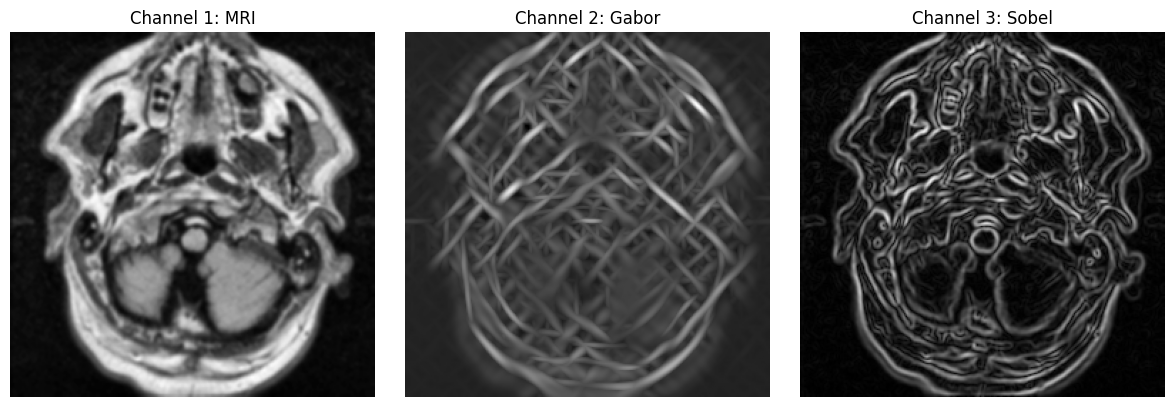

In [13]:
three_channel = create_three_channel_image(
    sample_image_path
)

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(three_channel[0], cmap="gray")
plt.title("Channel 1: MRI")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(three_channel[1], cmap="gray")
plt.title("Channel 2: Gabor")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(three_channel[2], cmap="gray")
plt.title("Channel 3: Sobel")
plt.axis("off")

plt.tight_layout()
plt.show()

In [14]:
IMAGE_SIZE = 128


class BrainTumorSegmentationDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_dir,
        mask_dir,
        augment=False
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.augment = augment

    def __len__(self):
        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = self.image_dir / row["image"]
        mask_path = self.mask_dir / row["mask"]

        image = create_three_channel_image(
            image_path
        )

        mask = cv2.imread(
            str(mask_path),
            cv2.IMREAD_GRAYSCALE
        )

        if mask is None:
            raise FileNotFoundError(
                f"Mask not found: {mask_path}"
            )

        mask = (mask > 0).astype(
            np.float32
        )

        # Resize
        resized_channels = []

        for channel in image:

            channel = cv2.resize(
                channel,
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=cv2.INTER_LINEAR
            )

            resized_channels.append(channel)

        image = np.stack(
            resized_channels,
            axis=0
        )

        mask = cv2.resize(
            mask,
            (IMAGE_SIZE, IMAGE_SIZE),
            interpolation=cv2.INTER_NEAREST
        )

        # Random horizontal flip
        if self.augment and random.random() < 0.5:

            image = np.flip(
                image,
                axis=2
            ).copy()

            mask = np.flip(
                mask,
                axis=1
            ).copy()

        # Random vertical flip
        if self.augment and random.random() < 0.2:

            image = np.flip(
                image,
                axis=1
            ).copy()

            mask = np.flip(
                mask,
                axis=0
            ).copy()

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        mask = torch.tensor(
            mask,
            dtype=torch.float32
        ).unsqueeze(0)

        return image, mask

In [15]:
def dice_score(
    prediction,
    target,
    smooth=1e-6
):

    prediction = prediction.reshape(
        prediction.shape[0],
        -1
    )

    target = target.reshape(
        target.shape[0],
        -1
    )

    intersection = (
        prediction * target
    ).sum(dim=1)

    dice = (
        2 * intersection + smooth
    ) / (
        prediction.sum(dim=1)
        +
        target.sum(dim=1)
        +
        smooth
    )

    return dice.mean()


def iou_score(
    prediction,
    target,
    smooth=1e-6
):

    prediction = prediction.reshape(
        prediction.shape[0],
        -1
    )

    target = target.reshape(
        target.shape[0],
        -1
    )

    intersection = (
        prediction * target
    ).sum(dim=1)

    union = (
        prediction.sum(dim=1)
        +
        target.sum(dim=1)
        -
        intersection
    )

    iou = (
        intersection + smooth
    ) / (
        union + smooth
    )

    return iou.mean()

In [16]:
bce_loss = nn.BCEWithLogitsLoss()


def dice_loss(
    logits,
    target
):

    probability = torch.sigmoid(
        logits
    )

    return 1 - dice_score(
        probability,
        target
    )


def combined_loss(
    logits,
    target
):

    bce = bce_loss(
        logits,
        target
    )

    dice = dice_loss(
        logits,
        target
    )

    return (
        0.5 * bce +
        0.5 * dice
    )

In [18]:
def generate_classification_labels(
    dataframe,
    mask_dir
):

    labels = []

    for _, row in dataframe.iterrows():

        mask_path = mask_dir / row["mask"]

        mask = cv2.imread(
            str(mask_path),
            cv2.IMREAD_GRAYSCALE
        )

        if mask is None:

            raise FileNotFoundError(
                mask_path
            )

        has_tumor = np.any(
            mask > 0
        )

        label = (
            1 if has_tumor else 0
        )

        labels.append(label)

    return np.array(labels)


train_labels = generate_classification_labels(
    train_df,
    MASK_DIR
)

val_labels = generate_classification_labels(
    val_df,
    MASK_DIR
)

print(
    "Training No Tumor:",
    np.sum(train_labels == 0)
)

print(
    "Training Tumor:",
    np.sum(train_labels == 1)
)

print(
    "Validation No Tumor:",
    np.sum(val_labels == 0)
)

print(
    "Validation Tumor:",
    np.sum(val_labels == 1)
)

Training No Tumor: 2036
Training Tumor: 1107
Validation No Tumor: 520
Validation Tumor: 266


In [19]:
class BrainTumorClassificationDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_dir,
        mask_dir,
        augment=False
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.image_dir = Path(image_dir)
        self.mask_dir = Path(mask_dir)
        self.augment = augment

        self.labels = (
            generate_classification_labels(
                self.dataframe,
                self.mask_dir
            )
        )

    def __len__(self):

        return len(self.dataframe)

    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = (
            self.image_dir /
            row["image"]
        )

        image = create_three_channel_image(
            image_path
        )

        resized_channels = []

        for channel in image:

            channel = cv2.resize(
                channel,
                (IMAGE_SIZE, IMAGE_SIZE),
                interpolation=cv2.INTER_LINEAR
            )

            resized_channels.append(
                channel
            )

        image = np.stack(
            resized_channels,
            axis=0
        )

        if (
            self.augment and
            random.random() < 0.5
        ):

            image = np.flip(
                image,
                axis=2
            ).copy()

        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        label = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return image, label

In [22]:
# CELL 19 — Research configuration and imports
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, roc_curve,
    precision_recall_curve, average_precision_score,
    balanced_accuracy_score, matthews_corrcoef
)
from pathlib import Path
import json, os, random, math, time

RESEARCH_DIR = Path("/kaggle/working/research_outputs")
FIG_DIR = RESEARCH_DIR / "figures"
CKPT_DIR = RESEARCH_DIR / "checkpoints"
SPLIT_DIR = RESEARCH_DIR / "splits"
for d in (RESEARCH_DIR, FIG_DIR, CKPT_DIR, SPLIT_DIR):
    d.mkdir(parents=True, exist_ok=True)

SEED = 42
IMAGE_SIZE = 128
BATCH_SIZE_SEG = 16
BATCH_SIZE_CLS = 32
SEG_EPOCHS = 30
CLS_EPOCHS = 20
PATIENCE = 7
NUM_WORKERS = 2

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
print("Device:", DEVICE)


Device: cuda


In [23]:
# CELL 20 — Build one source table and derive labels from masks
required_cols = {"image", "mask"}
if not required_cols.issubset(train_df.columns) or not required_cols.issubset(val_df.columns):
    raise ValueError(f"Each CSV must contain columns {required_cols}. Found train={train_df.columns.tolist()}, val={val_df.columns.tolist()}")

all_df = pd.concat([
    train_df.assign(original_split="train"),
    val_df.assign(original_split="validation")
], ignore_index=True).drop_duplicates(subset=["image", "mask"]).reset_index(drop=True)

def derive_label(mask_name):
    p = MASK_DIR / str(mask_name)
    m = cv2.imread(str(p), cv2.IMREAD_GRAYSCALE)
    if m is None: raise FileNotFoundError(f"Cannot read mask: {p}")
    return int(np.any(m > 0))

all_df["label"] = all_df["mask"].map(derive_label).astype(int)
print("Total unique pairs:", len(all_df))
print(all_df["label"].value_counts().sort_index().rename(index={0:"No tumor",1:"Tumor"}))

# Prefer a patient/group split when a usable identifier exists.
patient_candidates = [c for c in all_df.columns if any(k in c.lower() for k in ["patient", "subject", "case", "study", "volume"])]
patient_col = None
for c in patient_candidates:
    if all_df[c].notna().all() and all_df[c].nunique() > 1:
        patient_col = c; break
print("Candidate patient columns:", patient_candidates)
print("Selected grouping column:", patient_col)

if patient_col is not None:
    groups = all_df[patient_col].astype(str).values
    # Group-level stratification by majority/any-tumor group label.
    group_df = all_df.groupby(patient_col, dropna=False).agg(group_label=("label", "max")).reset_index()
    g_dev, g_test = train_test_split(group_df, test_size=0.15, random_state=SEED, stratify=group_df["group_label"] if group_df["group_label"].nunique()==2 else None)
    g_train, g_val = train_test_split(g_dev, test_size=0.15/0.85, random_state=SEED, stratify=g_dev["group_label"] if g_dev["group_label"].nunique()==2 else None)
    train_df_research = all_df[all_df[patient_col].isin(g_train[patient_col])].copy()
    val_df_research = all_df[all_df[patient_col].isin(g_val[patient_col])].copy()
    test_df = all_df[all_df[patient_col].isin(g_test[patient_col])].copy()
    split_mode = f"group-level using {patient_col}"
else:
    train_dev, test_df = train_test_split(all_df, test_size=0.15, random_state=SEED, stratify=all_df["label"])
    train_df_research, val_df_research = train_test_split(train_dev, test_size=0.15/0.85, random_state=SEED, stratify=train_dev["label"])
    split_mode = "slice-level stratified (no usable patient identifier found)"

train_df_research = train_df_research.sample(frac=1, random_state=SEED).reset_index(drop=True)
val_df_research = val_df_research.sample(frac=1, random_state=SEED).reset_index(drop=True)
test_df = test_df.sample(frac=1, random_state=SEED).reset_index(drop=True)

for name, df in [("train", train_df_research), ("validation", val_df_research), ("test", test_df)]:
    df.to_csv(SPLIT_DIR / f"{name}_research.csv", index=False)

split_summary = pd.DataFrame({
    "Split": ["Training", "Validation", "Test"],
    "Samples": [len(train_df_research), len(val_df_research), len(test_df)],
    "No Tumor": [(train_df_research.label==0).sum(), (val_df_research.label==0).sum(), (test_df.label==0).sum()],
    "Tumor": [(train_df_research.label==1).sum(), (val_df_research.label==1).sum(), (test_df.label==1).sum()]
})
split_summary["Percentage"] = 100*split_summary["Samples"]/split_summary["Samples"].sum()
split_summary.to_csv(RESEARCH_DIR/"split_summary.csv", index=False)
with open(RESEARCH_DIR/"split_metadata.json", "w") as f:
    json.dump({"seed":SEED, "split_mode":split_mode, "patient_column":patient_col, "total_pairs":len(all_df)}, f, indent=2, default=str)
display(split_summary)
print("Split mode:", split_mode)


Total unique pairs: 3929
label
No tumor    2556
Tumor       1373
Name: count, dtype: int64
Candidate patient columns: []
Selected grouping column: None


,Split,Samples,No Tumor,Tumor,Percentage
0,Training,2749,1788,961,69.966913
1,Validation,590,384,206,15.016544
2,Test,590,384,206,15.016544


Split mode: slice-level stratified (no usable patient identifier found)


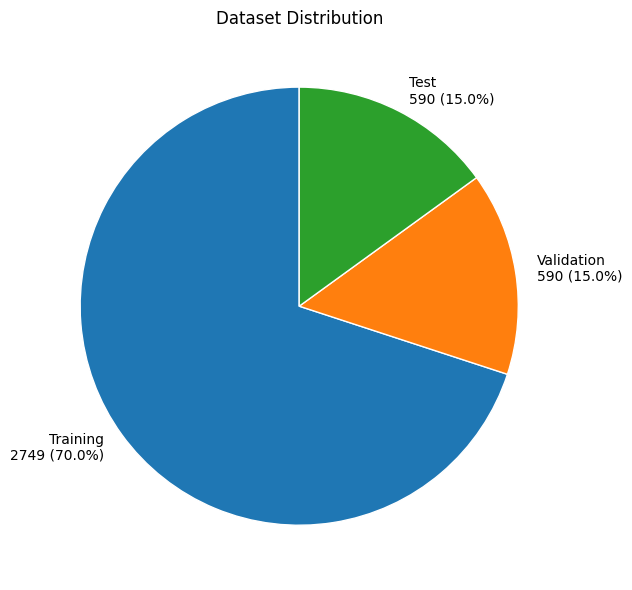

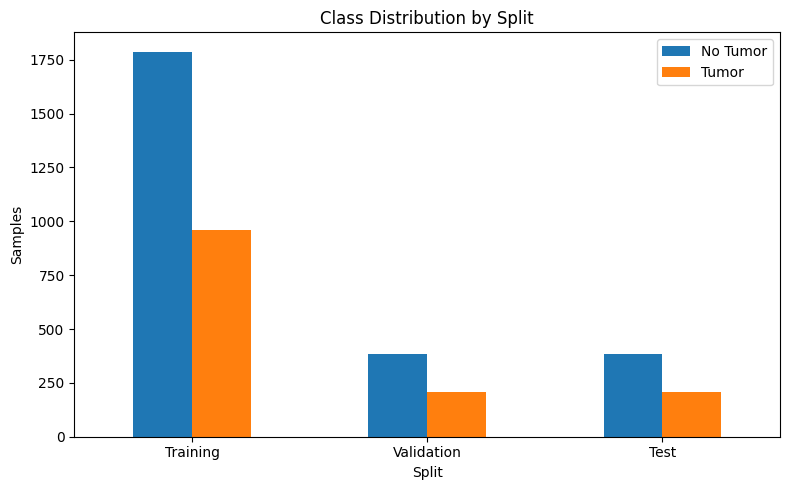

In [26]:
# CELL 21 — Dataset split figures
plt.figure(figsize=(7,6))
labels = [f"{r.Split}\n{r.Samples} ({r.Percentage:.1f}%)" for r in split_summary.itertuples()]
plt.pie(split_summary["Samples"], labels=labels, startangle=90, wedgeprops={"edgecolor":"white"})
plt.title("Dataset Distribution")
plt.tight_layout(); plt.savefig(FIG_DIR/"dataset_split_pie.png", dpi=300, bbox_inches="tight"); plt.show()

ax = split_summary.set_index("Split")[["No Tumor","Tumor"]].plot(kind="bar", figsize=(8,5))
ax.set_title("Class Distribution by Split"); ax.set_xlabel("Split"); ax.set_ylabel("Samples"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(FIG_DIR/"class_distribution_by_split.png", dpi=300, bbox_inches="tight"); plt.show()


In [27]:
# CELL 22 — Fresh datasets and loaders
research_train_seg = BrainTumorSegmentationDataset(train_df_research, IMAGE_DIR, MASK_DIR, augment=True)
research_val_seg = BrainTumorSegmentationDataset(val_df_research, IMAGE_DIR, MASK_DIR, augment=False)
research_test_seg = BrainTumorSegmentationDataset(test_df, IMAGE_DIR, MASK_DIR, augment=False)

research_train_loader = DataLoader(research_train_seg, batch_size=BATCH_SIZE_SEG, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
research_val_loader = DataLoader(research_val_seg, batch_size=BATCH_SIZE_SEG, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
research_test_loader = DataLoader(research_test_seg, batch_size=BATCH_SIZE_SEG, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())

research_train_cls = BrainTumorClassificationDataset(train_df_research, IMAGE_DIR, MASK_DIR, augment=True)
research_val_cls = BrainTumorClassificationDataset(val_df_research, IMAGE_DIR, MASK_DIR, augment=False)
research_test_cls = BrainTumorClassificationDataset(test_df, IMAGE_DIR, MASK_DIR, augment=False)
research_train_cls_loader = DataLoader(research_train_cls, batch_size=BATCH_SIZE_CLS, shuffle=True, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
research_val_cls_loader = DataLoader(research_val_cls, batch_size=BATCH_SIZE_CLS, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
research_test_cls_loader = DataLoader(research_test_cls, batch_size=BATCH_SIZE_CLS, shuffle=False, num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available())
print("Segmentation sizes:", len(research_train_seg), len(research_val_seg), len(research_test_seg))
print("Classification sizes:", len(research_train_cls), len(research_val_cls), len(research_test_cls))


Segmentation sizes: 2749 590 590
Classification sizes: 2749 590 590


In [28]:
# ============================================================
# NeuroScan AI - Representative MRI Figure Package
# 36 REAL MRI IMAGES
# 6 Tumor + 6 No Tumor from each research split
#
# Run immediately AFTER the dataset split cell.
# No model training required.
# ============================================================

from pathlib import Path
import pandas as pd
import shutil

PACKAGE_DIR = Path("/kaggle/working/neuroscan_figure_package")
PACKAGE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Research splits already created by the notebook
# ------------------------------------------------------------

split_data = {
    "training": train_df_research,
    "validation": val_df_research,
    "test": test_df
}

# ------------------------------------------------------------
# Save exact research split CSVs
# ------------------------------------------------------------

for split_name, df in split_data.items():

    df.to_csv(
        PACKAGE_DIR / f"{split_name}_research.csv",
        index=False
    )

# ------------------------------------------------------------
# Select 6 Tumor + 6 No Tumor from EACH split
# ------------------------------------------------------------

selected_records = []

for split_name, df in split_data.items():

    print(f"\n{'='*60}")
    print(f"PROCESSING {split_name.upper()} SPLIT")
    print(f"{'='*60}")

    split_dir = PACKAGE_DIR / split_name
    split_dir.mkdir(parents=True, exist_ok=True)

    tumor_df = df[df["label"] == 1]
    no_tumor_df = df[df["label"] == 0]

    print("Available Tumor:", len(tumor_df))
    print("Available No Tumor:", len(no_tumor_df))

    # Select 6 from each class
    tumor_samples = tumor_df.sample(
        n=min(6, len(tumor_df)),
        random_state=42
    )

    no_tumor_samples = no_tumor_df.sample(
        n=min(6, len(no_tumor_df)),
        random_state=42
    )

    # --------------------------------------------------------
    # Copy images
    # --------------------------------------------------------

    for _, row in pd.concat(
        [no_tumor_samples, tumor_samples]
    ).iterrows():

        image_name = str(row["image"])
        source_path = IMAGE_DIR / image_name

        if not source_path.exists():
            print("WARNING - image not found:")
            print(source_path)
            continue

        label = int(row["label"])

        if label == 1:
            label_name = "Tumor"
        else:
            label_name = "No_Tumor"

        destination_name = (
            f"{split_name}_{label_name}_{Path(image_name).name}"
        )

        destination_path = split_dir / destination_name

        shutil.copy2(
            source_path,
            destination_path
        )

        selected_records.append({
            "split": split_name,
            "label": label,
            "diagnosis": label_name,
            "original_image": image_name,
            "copied_image": str(
                Path(split_name) / destination_name
            )
        })

# ------------------------------------------------------------
# Create manifest
# ------------------------------------------------------------

manifest_df = pd.DataFrame(selected_records)

manifest_df.to_csv(
    PACKAGE_DIR / "selected_images_manifest.csv",
    index=False
)

# ------------------------------------------------------------
# Display summary
# ------------------------------------------------------------

print("\n\nFINAL IMAGE SELECTION")
print("=" * 60)

summary = (
    manifest_df
    .groupby(["split", "diagnosis"])
    .size()
    .unstack(fill_value=0)
)

display(summary)

print("\nTotal images:", len(manifest_df))

# ------------------------------------------------------------
# Create ZIP
# ------------------------------------------------------------

zip_path = shutil.make_archive(
    "/kaggle/working/neuroscan_figure_package",
    "zip",
    PACKAGE_DIR
)

print("\nZIP PACKAGE CREATED:")
print(zip_path)


PROCESSING TRAINING SPLIT
Available Tumor: 961
Available No Tumor: 1788

PROCESSING VALIDATION SPLIT
Available Tumor: 206
Available No Tumor: 384

PROCESSING TEST SPLIT
Available Tumor: 206
Available No Tumor: 384


FINAL IMAGE SELECTION


diagnosis,No_Tumor,Tumor
split,,
test,6,6
training,6,6
validation,6,6



Total images: 36

ZIP PACKAGE CREATED:
/kaggle/working/neuroscan_figure_package.zip


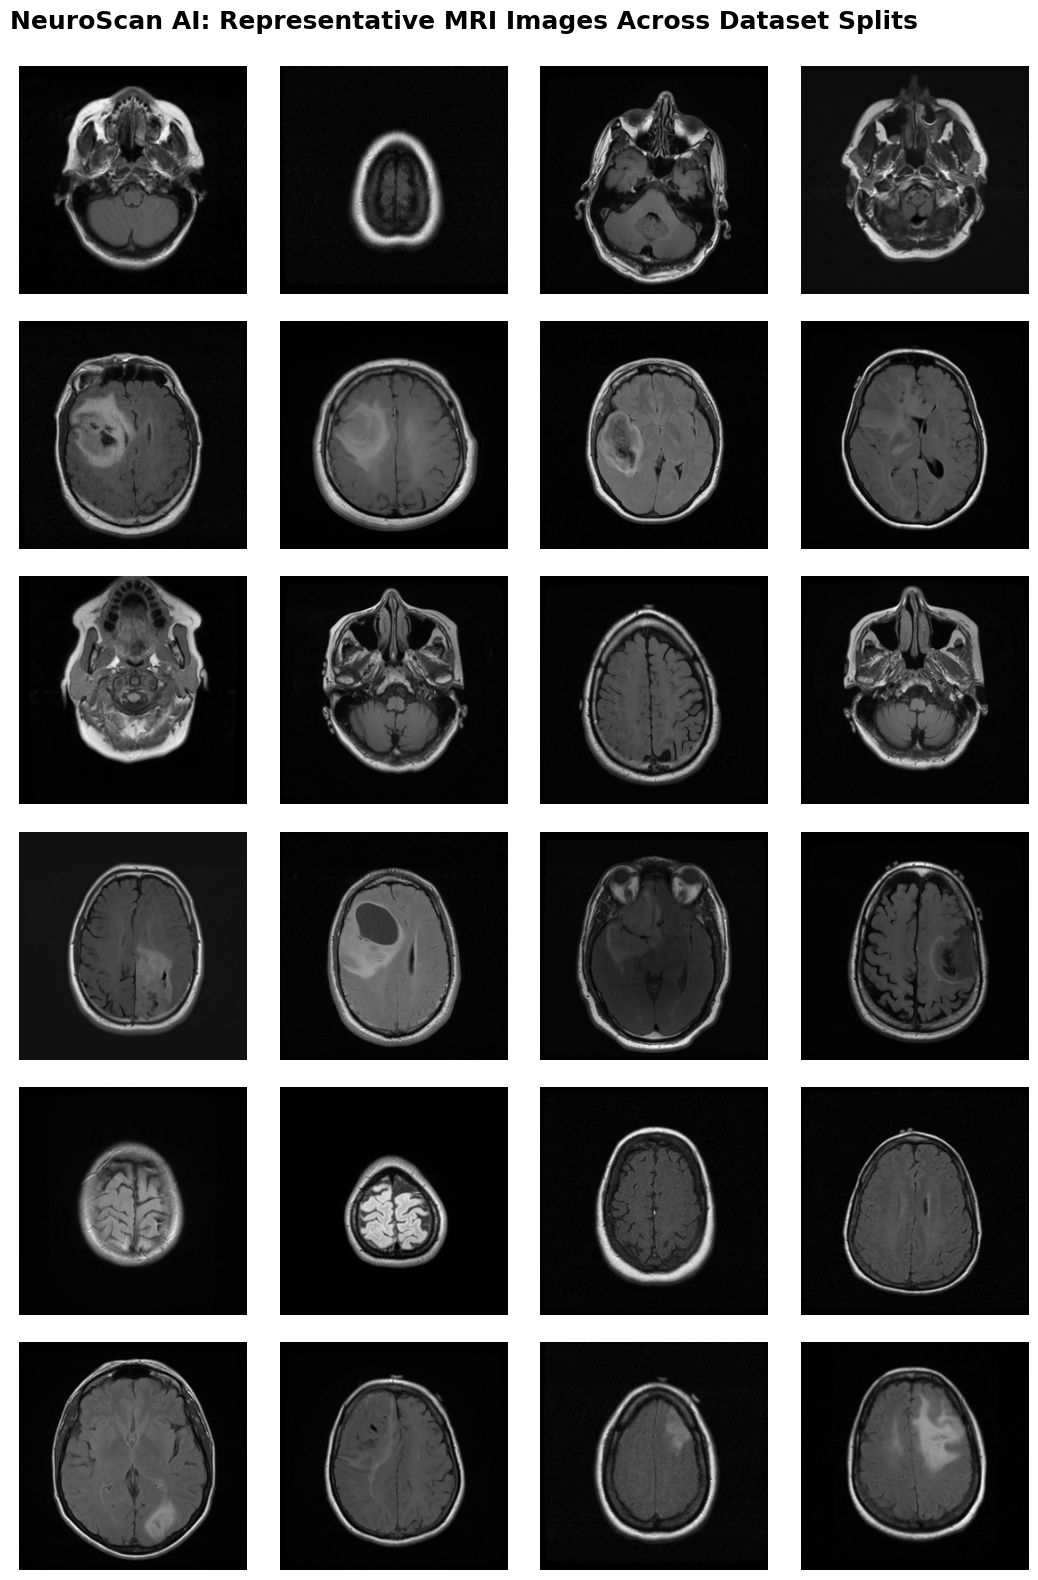

Figure saved:
/kaggle/working/neuroscan_figure/neuroscan_mri_6x4_grid.png
/kaggle/working/neuroscan_figure/neuroscan_mri_6x4_grid.pdf


In [30]:
# ============================================================
# NeuroScan AI - Simple 6 x 4 MRI Dataset Distribution Figure
# 24 REAL MRI IMAGES
# 4 images from each split/diagnosis combination
# ============================================================

import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

OUTPUT_DIR = Path("/kaggle/working/neuroscan_figure")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Define the six groups
# ------------------------------------------------------------

groups = [
    ("Training - No Tumor", train_df_research, 0),
    ("Training - Tumor", train_df_research, 1),

    ("Validation - No Tumor", val_df_research, 0),
    ("Validation - Tumor", val_df_research, 1),

    ("Test - No Tumor", test_df, 0),
    ("Test - Tumor", test_df, 1),
]

# ------------------------------------------------------------
# Select 4 images from each group
# ------------------------------------------------------------

selected_groups = {}

for group_name, df, label in groups:

    group_df = df[df["label"] == label]

    selected_groups[group_name] = group_df.sample(
        n=4,
        random_state=42
    )

# ------------------------------------------------------------
# Create simple 6 x 4 grid
# ------------------------------------------------------------

fig, axes = plt.subplots(
    6,
    4,
    figsize=(12, 16)
)

fig.suptitle(
    "NeuroScan AI: Representative MRI Images Across Dataset Splits",
    fontsize=18,
    fontweight="bold",
    y=0.995
)

# ------------------------------------------------------------
# Populate grid
# ------------------------------------------------------------

for row, (group_name, df) in enumerate(
    selected_groups.items()
):

    for col, (_, sample) in enumerate(
        df.iterrows()
    ):

        ax = axes[row, col]

        image_name = str(sample["image"])
        image_path = IMAGE_DIR / image_name

        image = Image.open(
            image_path
        ).convert("L")

        ax.imshow(
            image,
            cmap="gray"
        )

        ax.axis("off")

        # Add group label only to first image
        if col == 0:
            ax.set_ylabel(
                group_name,
                fontsize=11,
                fontweight="bold",
                rotation=90,
                labelpad=15
            )

# ------------------------------------------------------------
# Adjust layout
# ------------------------------------------------------------

plt.subplots_adjust(
    left=0.12,
    right=0.98,
    top=0.96,
    bottom=0.02,
    wspace=0.04,
    hspace=0.12
)

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

plt.savefig(
    OUTPUT_DIR / "neuroscan_mri_6x4_grid.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.savefig(
    OUTPUT_DIR / "neuroscan_mri_6x4_grid.pdf",
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print("Figure saved:")
print(
    OUTPUT_DIR /
    "neuroscan_mri_6x4_grid.png"
)

print(
    OUTPUT_DIR /
    "neuroscan_mri_6x4_grid.pdf"
)

In [22]:
# ============================================================
# SEGMENTATION TRAINING — CORRECTED
# ============================================================

def build_seg_model():
    return smp.UnetPlusPlus(
        encoder_name="resnet34",
        encoder_weights=None,
        in_channels=3,
        classes=1,
        activation=None
    ).to(DEVICE)


def seg_epoch(model, loader, optimizer=None):

    is_train = optimizer is not None
    model.train(is_train)

    total_loss = 0.0
    total_dice = 0.0
    total_iou = 0.0

    for images, masks in loader:

        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        if is_train:
            optimizer.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(is_train):

            logits = model(images)

            loss = combined_loss(
                logits,
                masks
            )

            probs = torch.sigmoid(logits)

            pred = (
                probs >= 0.5
            ).float()

            if is_train:

                loss.backward()

                torch.nn.utils.clip_grad_norm_(
                    model.parameters(),
                    max_norm=1.0
                )

                optimizer.step()

        batch_size = images.size(0)

        total_loss += (
            loss.item() * batch_size
        )

        total_dice += (
            dice_score(pred, masks).item()
            * batch_size
        )

        total_iou += (
            iou_score(pred, masks).item()
            * batch_size
        )

    n = len(loader.dataset)

    return {
        "loss": total_loss / n,
        "dice": total_dice / n,
        "iou": total_iou / n
    }


# ------------------------------------------------------------
# Initialize model and optimizer
# ------------------------------------------------------------

seg_model = build_seg_model()

seg_optimizer = torch.optim.AdamW(
    seg_model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)

seg_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    seg_optimizer,
    mode="max",
    factor=0.5,
    patience=3
)

seg_history = {
    "train_loss": [],
    "train_dice": [],
    "train_iou": [],
    "val_loss": [],
    "val_dice": [],
    "val_iou": [],
    "lr": []
}

best_val_dice = -1.0
bad_epochs = 0

BEST_SEG = CKPT_DIR / "unetplusplus_best_validation.pth"


# ------------------------------------------------------------
# Training loop
# ------------------------------------------------------------

for epoch in range(1, SEG_EPOCHS + 1):

    tr = seg_epoch(
        seg_model,
        research_train_loader,
        seg_optimizer
    )

    va = seg_epoch(
        seg_model,
        research_val_loader
    )

    seg_scheduler.step(va["dice"])

    metrics = {
        "train_loss": tr["loss"],
        "train_dice": tr["dice"],
        "train_iou": tr["iou"],
        "val_loss": va["loss"],
        "val_dice": va["dice"],
        "val_iou": va["iou"],
        "lr": seg_optimizer.param_groups[0]["lr"]
    }

    for key, value in metrics.items():
        seg_history[key].append(float(value))

    print(
        f"Epoch {epoch:02d}/{SEG_EPOCHS} | "
        f"Train Dice: {tr['dice']:.4f} | "
        f"Val Dice: {va['dice']:.4f} | "
        f"Val IoU: {va['iou']:.4f}"
    )

    if va["dice"] > best_val_dice:

        best_val_dice = va["dice"]
        bad_epochs = 0

        torch.save(
            {
                "model_state_dict": seg_model.state_dict(),
                "epoch": epoch,
                "val_metrics": va
            },
            BEST_SEG
        )

    else:

        bad_epochs += 1

    if bad_epochs >= PATIENCE:

        print("Early stopping segmentation.")
        break


# ------------------------------------------------------------
# Save history and load best model
# ------------------------------------------------------------

with open(
    RESEARCH_DIR / "segmentation_history.json",
    "w"
) as f:

    json.dump(
        seg_history,
        f,
        indent=2
    )


seg_ckpt = torch.load(
    BEST_SEG,
    map_location=DEVICE
)

seg_model.load_state_dict(
    seg_ckpt["model_state_dict"]
)

print(
    "Best validation Dice:",
    seg_ckpt["val_metrics"]["dice"]
)

Epoch 01/30 | Train Dice: 0.4490 | Val Dice: 0.5413 | Val IoU: 0.4991
Epoch 02/30 | Train Dice: 0.6117 | Val Dice: 0.6404 | Val IoU: 0.6014
Epoch 03/30 | Train Dice: 0.6346 | Val Dice: 0.5417 | Val IoU: 0.5009
Epoch 04/30 | Train Dice: 0.6382 | Val Dice: 0.7472 | Val IoU: 0.7080
Epoch 05/30 | Train Dice: 0.6252 | Val Dice: 0.5828 | Val IoU: 0.5423
Epoch 06/30 | Train Dice: 0.6544 | Val Dice: 0.6626 | Val IoU: 0.6222
Epoch 07/30 | Train Dice: 0.6446 | Val Dice: 0.5219 | Val IoU: 0.4830
Epoch 08/30 | Train Dice: 0.6936 | Val Dice: 0.8044 | Val IoU: 0.7679
Epoch 09/30 | Train Dice: 0.6627 | Val Dice: 0.6711 | Val IoU: 0.6334
Epoch 10/30 | Train Dice: 0.6762 | Val Dice: 0.4064 | Val IoU: 0.3676
Epoch 11/30 | Train Dice: 0.7180 | Val Dice: 0.8077 | Val IoU: 0.7738
Epoch 12/30 | Train Dice: 0.7258 | Val Dice: 0.6687 | Val IoU: 0.6327
Epoch 13/30 | Train Dice: 0.7398 | Val Dice: 0.7826 | Val IoU: 0.7470
Epoch 14/30 | Train Dice: 0.7304 | Val Dice: 0.7346 | Val IoU: 0.6999
Epoch 15/30 | Train 

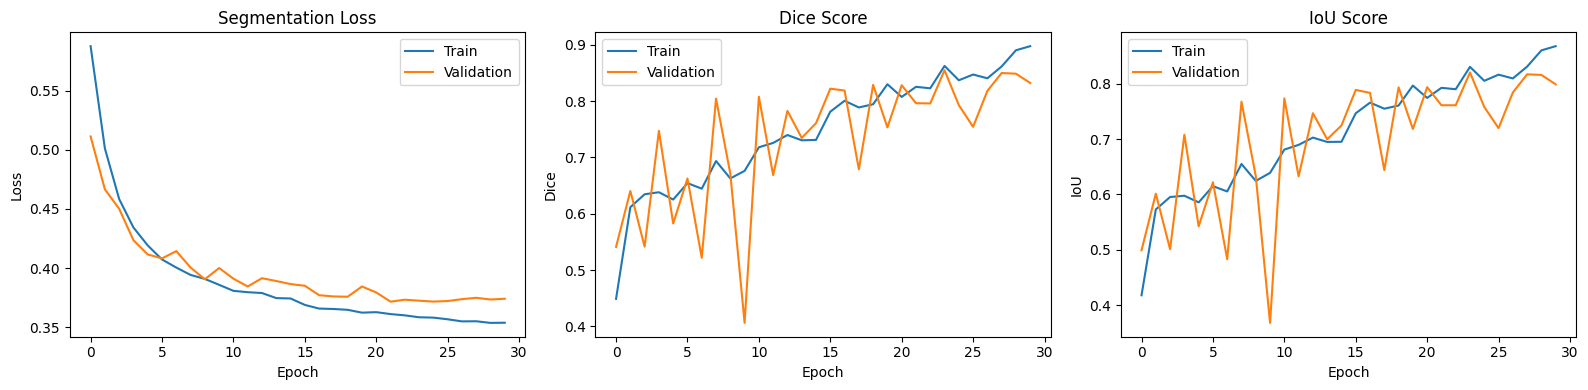

In [23]:
# CELL 24 — Segmentation training curves
fig, axes=plt.subplots(1,3,figsize=(16,4))
for ax, a, b, title, ylabel in [
    (axes[0],"train_loss","val_loss","Segmentation Loss","Loss"),
    (axes[1],"train_dice","val_dice","Dice Score","Dice"),
    (axes[2],"train_iou","val_iou","IoU Score","IoU")]:
    ax.plot(seg_history[a],label="Train"); ax.plot(seg_history[b],label="Validation"); ax.set_title(title); ax.set_xlabel("Epoch"); ax.set_ylabel(ylabel); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR/"segmentation_training_curves.png",dpi=300,bbox_inches="tight"); plt.show()


HELD-OUT TEST SEGMENTATION RESULTS
pixel_accuracy          : 0.996705
pixel_precision         : 0.841024
pixel_recall            : 0.841836
pixel_specificity       : 0.998330
pixel_dice              : 0.841430
pixel_iou               : 0.726266
mean_case_dice          : 0.824069
median_case_dice        : 1.000000
mean_case_iou           : 0.790648
median_case_iou         : 1.000000
mean_case_precision     : 0.832210
median_case_precision   : 1.000000
mean_case_recall        : 0.832326
median_case_recall      : 1.000000


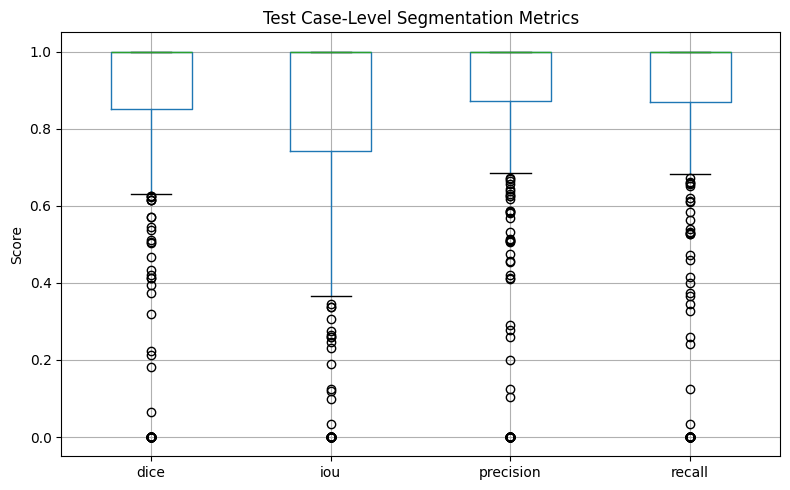

In [24]:
# CELL 25 — Held-out test segmentation metrics and distributions

def evaluate_segmentation_test(model, loader):
    model.eval(); TP=TN=FP=FN=0; rows=[]
    with torch.no_grad():
        for images,masks in loader:
            logits=model(images.to(DEVICE)); pred=(torch.sigmoid(logits)>=0.5).cpu().numpy()[:,0].astype(bool); true=(masks.numpy()[:,0]>=0.5)
            for p,t in zip(pred,true):
                inter=np.logical_and(p,t).sum(); union=np.logical_or(p,t).sum(); pa=p.sum(); ta=t.sum()
                dice=1.0 if pa==0 and ta==0 else 2*inter/(pa+ta+1e-8); iou=1.0 if union==0 else inter/(union+1e-8)
                prec=1.0 if pa==0 and ta==0 else inter/(pa+1e-8); rec=1.0 if ta==0 and pa==0 else (inter/(ta+1e-8) if ta else 0.0)
                rows.append({"dice":dice,"iou":iou,"precision":prec,"recall":rec,"true_tumor":int(ta>0),"pred_tumor":int(pa>0)})
            p=torch.from_numpy(pred); t=torch.from_numpy(true); TP += int((p&t).sum()); TN += int((~p&~t).sum()); FP += int((p&~t).sum()); FN += int((~p&t).sum())
    eps=1e-8; case_df=pd.DataFrame(rows)
    metrics={"pixel_accuracy":(TP+TN)/(TP+TN+FP+FN+eps),"pixel_precision":TP/(TP+FP+eps),"pixel_recall":TP/(TP+FN+eps),"pixel_specificity":TN/(TN+FP+eps),"pixel_dice":2*TP/(2*TP+FP+FN+eps),"pixel_iou":TP/(TP+FP+FN+eps)}
    for c in ["dice","iou","precision","recall"]: metrics[f"mean_case_{c}"]=float(case_df[c].mean()); metrics[f"median_case_{c}"]=float(case_df[c].median())
    return metrics,case_df

test_seg_metrics,test_seg_cases=evaluate_segmentation_test(seg_model,research_test_loader)
pd.DataFrame([test_seg_metrics]).to_csv(RESEARCH_DIR/"test_segmentation_metrics.csv",index=False)
test_seg_cases.to_csv(RESEARCH_DIR/"test_segmentation_case_metrics.csv",index=False)
print("HELD-OUT TEST SEGMENTATION RESULTS"); [print(f"{k:24s}: {v:.6f}") for k,v in test_seg_metrics.items()]
test_seg_cases[["dice","iou","precision","recall"]].boxplot(figsize=(8,5)); plt.title("Test Case-Level Segmentation Metrics"); plt.ylabel("Score"); plt.tight_layout(); plt.savefig(FIG_DIR/"test_segmentation_metric_boxplot.png",dpi=300,bbox_inches="tight"); plt.show()


In [25]:
# CELL 26 — Classifier training and validation checkpointing

def build_cls_model():
    m = models.resnet18(
        weights=models.ResNet18_Weights.DEFAULT
    )

    m.fc = nn.Linear(
        m.fc.in_features,
        1
    )

    return m.to(DEVICE)

def cls_eval(model,loader,criterion):
    model.eval(); loss_sum=0.; y=[]; p=[]
    with torch.no_grad():
        for x,t in loader:
            x=x.to(DEVICE); t=t.float().view(-1,1).to(DEVICE); z=model(x).view(-1,1); loss=criterion(z,t); loss_sum+=loss.item()*x.size(0); y.extend(t.cpu().numpy().ravel().astype(int)); p.extend(torch.sigmoid(z).cpu().numpy().ravel())
    y=np.array(y); p=np.array(p); pred=(p>=0.5).astype(int)
    return {"loss":loss_sum/len(loader.dataset),"accuracy":accuracy_score(y,pred),"precision":precision_score(y,pred,zero_division=0),"recall":recall_score(y,pred,zero_division=0),"f1":f1_score(y,pred,zero_division=0),"auc":roc_auc_score(y,p) if len(np.unique(y))==2 else np.nan,"ap":average_precision_score(y,p) if len(np.unique(y))==2 else np.nan,"labels":y,"probabilities":p,"predictions":pred}

num_neg=int((train_df_research.label==0).sum()); num_pos=int((train_df_research.label==1).sum()); pos_weight=torch.tensor([num_neg/max(num_pos,1)],device=DEVICE,dtype=torch.float32)
cls_model=build_cls_model(); cls_criterion=nn.BCEWithLogitsLoss(pos_weight=pos_weight); cls_optimizer=torch.optim.AdamW(cls_model.parameters(),lr=1e-4,weight_decay=1e-4); cls_scheduler=torch.optim.lr_scheduler.ReduceLROnPlateau(cls_optimizer,mode="max",factor=0.5,patience=3)
cls_history={k:[] for k in ["train_loss","train_accuracy","train_f1","val_loss","val_accuracy","val_precision","val_recall","val_f1","val_auc","val_ap","lr"]}; best_auc=-1.; bad=0; BEST_CLS=CKPT_DIR/"resnet18_best_validation.pth"
for epoch in range(1,CLS_EPOCHS+1):
    cls_model.train(); loss_sum=0.; yt=[]; yp=[]
    for x,t in research_train_cls_loader:
        x=x.to(DEVICE); t=t.float().view(-1,1).to(DEVICE); cls_optimizer.zero_grad(set_to_none=True); z=cls_model(x).view(-1,1); loss=cls_criterion(z,t); loss.backward(); torch.nn.utils.clip_grad_norm_(cls_model.parameters(),1.0); cls_optimizer.step(); loss_sum+=loss.item()*x.size(0); yt.extend(t.detach().cpu().numpy().ravel().astype(int)); yp.extend((torch.sigmoid(z)>=0.5).detach().cpu().numpy().ravel().astype(int))
    tr_loss=loss_sum/len(research_train_cls_loader.dataset); tr_acc=accuracy_score(yt,yp); tr_f1=f1_score(yt,yp,zero_division=0)
    va=cls_eval(cls_model,research_val_cls_loader,cls_criterion); cls_scheduler.step(va["auc"] if np.isfinite(va["auc"]) else 0.)
    for k,v in [("train_loss",tr_loss),("train_accuracy",tr_acc),("train_f1",tr_f1),("val_loss",va["loss"]),("val_accuracy",va["accuracy"]),("val_precision",va["precision"]),("val_recall",va["recall"]),("val_f1",va["f1"]),("val_auc",va["auc"]),("val_ap",va["ap"]),("lr",cls_optimizer.param_groups[0]["lr"])]: cls_history[k].append(float(v) if np.isfinite(v) else None)
    print(f"Epoch {epoch:02d}/{CLS_EPOCHS} | train F1={tr_f1:.4f} | val F1={va['f1']:.4f} | val AUC={va['auc']:.4f}")
    score=va["auc"] if np.isfinite(va["auc"]) else va["f1"]
    if score>best_auc: best_auc=score; bad=0; torch.save({"model_state_dict":cls_model.state_dict(),"epoch":epoch,"val_metrics":{k:v for k,v in va.items() if k not in ["labels","probabilities","predictions"]}},BEST_CLS)
    else: bad+=1
    if bad>=PATIENCE: print("Early stopping classifier."); break
# Save training history
with open(
    RESEARCH_DIR / "classification_history.json",
    "w"
) as f:
    json.dump(cls_history, f, indent=2)


# Load best classifier checkpoint
cls_ckpt = torch.load(
    BEST_CLS,
    map_location=DEVICE,
    weights_only=False
)

cls_model.load_state_dict(
    cls_ckpt["model_state_dict"]
)

cls_model.eval()

print(
    "Best validation selection score:",
    best_auc
)

print(
    "Best checkpoint epoch:",
    cls_ckpt["epoch"]
)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 217MB/s]


Epoch 01/20 | train F1=0.7814 | val F1=0.8221 | val AUC=0.9490
Epoch 02/20 | train F1=0.8835 | val F1=0.8598 | val AUC=0.9701
Epoch 03/20 | train F1=0.9287 | val F1=0.8615 | val AUC=0.9681
Epoch 04/20 | train F1=0.9565 | val F1=0.8472 | val AUC=0.9556
Epoch 05/20 | train F1=0.9672 | val F1=0.8432 | val AUC=0.9538
Epoch 06/20 | train F1=0.9749 | val F1=0.8729 | val AUC=0.9768
Epoch 07/20 | train F1=0.9780 | val F1=0.8878 | val AUC=0.9813
Epoch 08/20 | train F1=0.9808 | val F1=0.8911 | val AUC=0.9764
Epoch 09/20 | train F1=0.9876 | val F1=0.8866 | val AUC=0.9690
Epoch 10/20 | train F1=0.9912 | val F1=0.8837 | val AUC=0.9789
Epoch 11/20 | train F1=0.9870 | val F1=0.8586 | val AUC=0.9648
Epoch 12/20 | train F1=0.9927 | val F1=0.9005 | val AUC=0.9837
Epoch 13/20 | train F1=0.9990 | val F1=0.9086 | val AUC=0.9724
Epoch 14/20 | train F1=0.9990 | val F1=0.9082 | val AUC=0.9768
Epoch 15/20 | train F1=0.9990 | val F1=0.9086 | val AUC=0.9726
Epoch 16/20 | train F1=0.9990 | val F1=0.9069 | val AUC

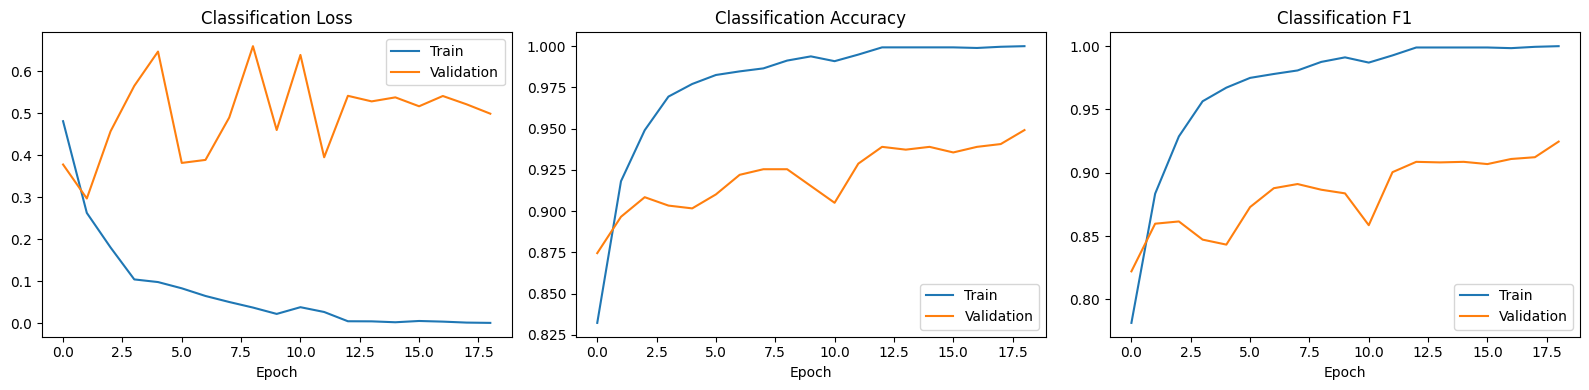

HELD-OUT TEST CLASSIFICATION RESULTS
loss            : 0.482951
accuracy        : 0.932203
precision       : 0.884259
recall          : 0.927184
f1              : 0.905213
auc             : 0.970779
ap              : 0.967910


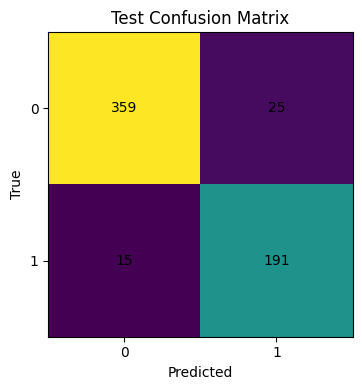

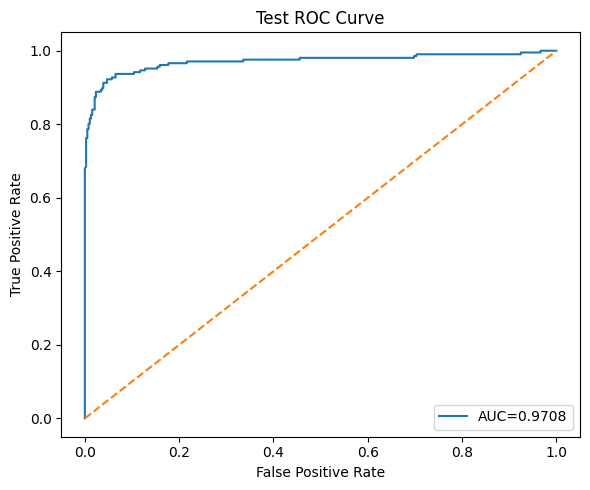

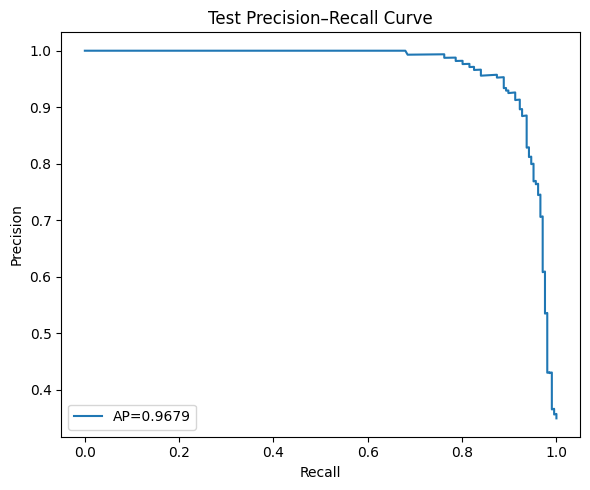

In [26]:
# CELL 27 — Classification curves and held-out test metrics
fig,axes=plt.subplots(1,3,figsize=(16,4))
for ax,a,b,title in [(axes[0],"train_loss","val_loss","Classification Loss"),(axes[1],"train_accuracy","val_accuracy","Classification Accuracy"),(axes[2],"train_f1","val_f1","Classification F1")]:
    ax.plot(cls_history[a],label="Train"); ax.plot(cls_history[b],label="Validation"); ax.set_title(title); ax.set_xlabel("Epoch"); ax.legend()
plt.tight_layout(); plt.savefig(FIG_DIR/"classification_training_curves.png",dpi=300,bbox_inches="tight"); plt.show()

test_cls=cls_eval(cls_model,research_test_cls_loader,cls_criterion)
test_cls_metrics={k:float(v) for k,v in test_cls.items() if k not in ["labels","probabilities","predictions"] and np.isscalar(v) and np.isfinite(v)}
pd.DataFrame([test_cls_metrics]).to_csv(RESEARCH_DIR/"test_classification_metrics.csv",index=False)
print("HELD-OUT TEST CLASSIFICATION RESULTS"); [print(f"{k:16s}: {v:.6f}") for k,v in test_cls_metrics.items()]

cm=confusion_matrix(test_cls["labels"],test_cls["predictions"])
fig,ax=plt.subplots(figsize=(5,4)); ax.imshow(cm); ax.set_title("Test Confusion Matrix"); ax.set_xlabel("Predicted"); ax.set_ylabel("True"); ax.set_xticks([0,1]); ax.set_yticks([0,1])
for (i,j),v in np.ndenumerate(cm): ax.text(j,i,str(v),ha="center",va="center")
plt.tight_layout(); plt.savefig(FIG_DIR/"test_confusion_matrix.png",dpi=300,bbox_inches="tight"); plt.show()

fpr,tpr,_=roc_curve(test_cls["labels"],test_cls["probabilities"]); plt.figure(figsize=(6,5)); plt.plot(fpr,tpr,label=f"AUC={test_cls['auc']:.4f}"); plt.plot([0,1],[0,1],"--"); plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("Test ROC Curve"); plt.legend(); plt.tight_layout(); plt.savefig(FIG_DIR/"test_roc_curve.png",dpi=300,bbox_inches="tight"); plt.show()

pr,rc,_=precision_recall_curve(test_cls["labels"],test_cls["probabilities"]); plt.figure(figsize=(6,5)); plt.plot(rc,pr,label=f"AP={test_cls['ap']:.4f}"); plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Test Precision–Recall Curve"); plt.legend(); plt.tight_layout(); plt.savefig(FIG_DIR/"test_precision_recall_curve.png",dpi=300,bbox_inches="tight"); plt.show()


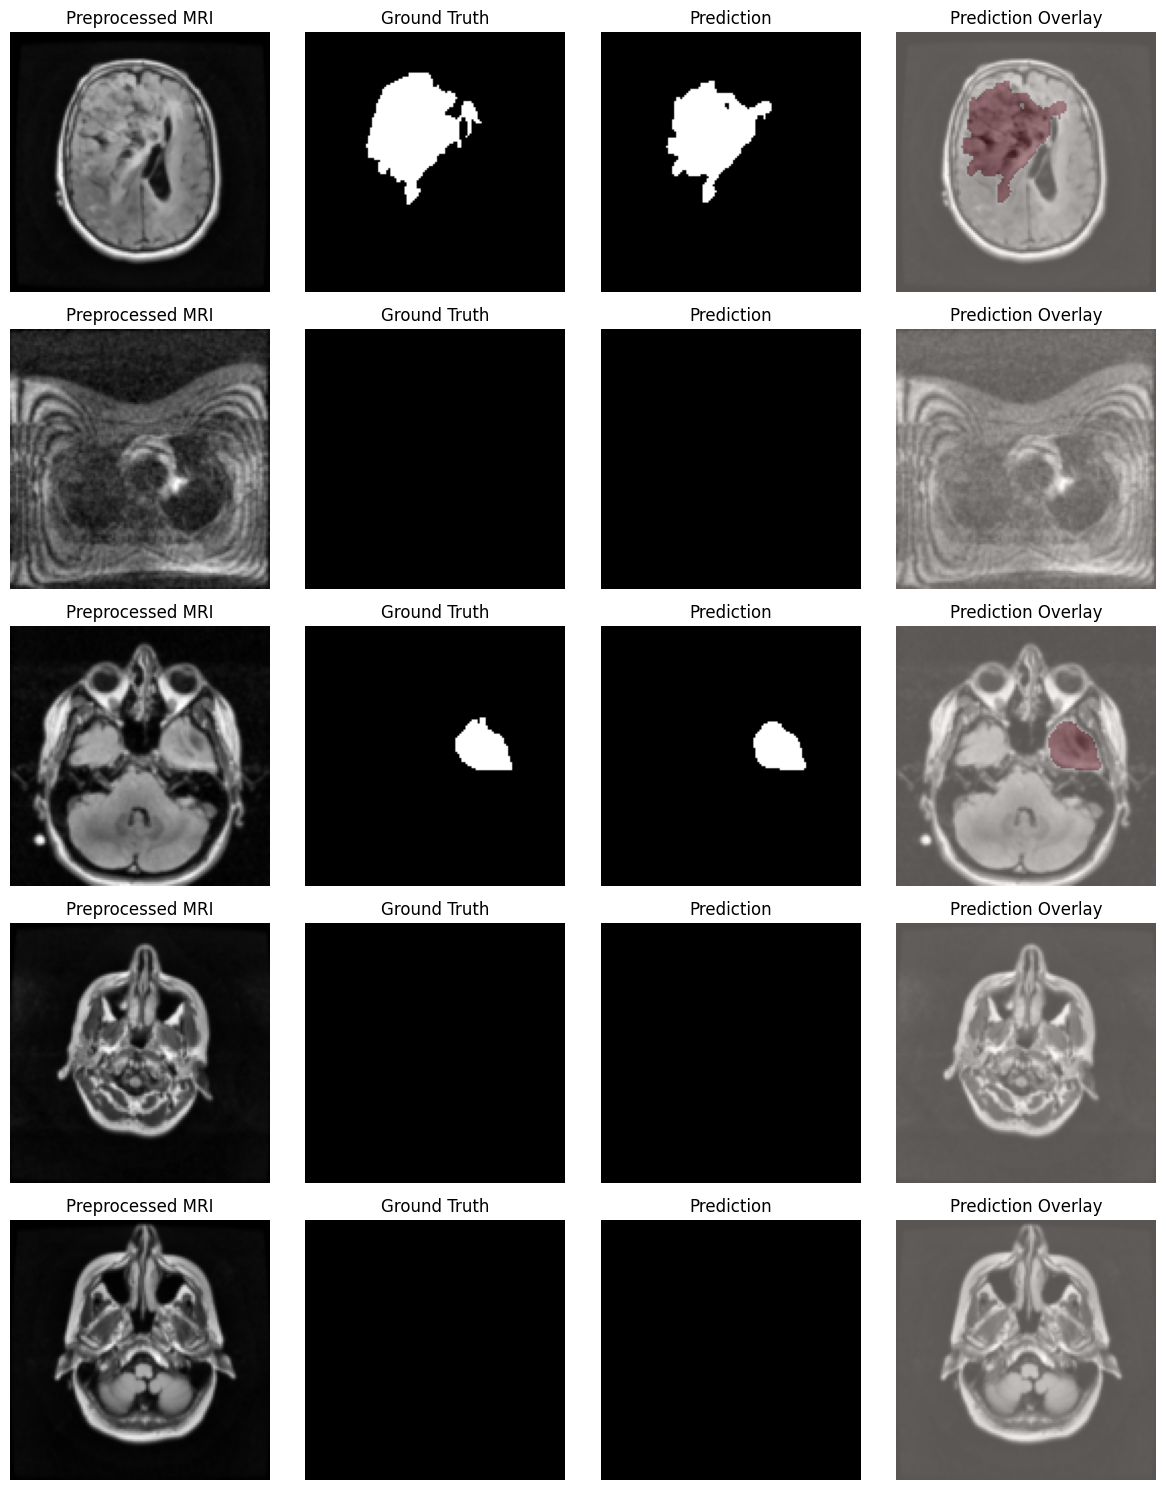

In [28]:
# CELL 28 — Qualitative test segmentation figure
seg_model.eval(); batch_images,batch_masks=next(iter(research_test_loader))
with torch.no_grad(): batch_probs=torch.sigmoid(seg_model(batch_images.to(DEVICE))).cpu()
n_show=min(5,len(batch_images)); fig,axes=plt.subplots(n_show,4,figsize=(12,3*n_show)); axes=np.atleast_2d(axes)
for i in range(n_show):
    mri=batch_images[i,0].numpy(); true=batch_masks[i,0].numpy(); pred=(batch_probs[i,0].numpy()>=0.5).astype(float)
    for j,(img,title,cmap) in enumerate([(mri,"Preprocessed MRI","gray"),(true,"Ground Truth","gray"),(pred,"Prediction","gray")]): axes[i,j].imshow(img,cmap=cmap); axes[i,j].set_title(title); axes[i,j].axis("off")
    axes[i,3].imshow(mri,cmap="gray"); axes[i,3].imshow(pred,alpha=0.35,cmap="Reds"); axes[i,3].set_title("Prediction Overlay"); axes[i,3].axis("off")
plt.tight_layout(); plt.savefig(FIG_DIR/"test_qualitative_segmentation.png",dpi=300,bbox_inches="tight"); plt.show()


In [29]:
# CELL 29 — Consolidated export and reproducibility manifest
rows=[]
for task,metrics in [("Segmentation",test_seg_metrics),("Classification",test_cls_metrics)]:
    for metric,value in metrics.items(): rows.append({"Task":task,"Metric":metric,"Value":float(value),"Evaluation":"Held-out test"})
overall=pd.DataFrame(rows); overall.to_csv(RESEARCH_DIR/"overall_test_results.csv",index=False); display(overall)

torch.save({"model_state_dict":seg_model.state_dict(),"best_validation_dice":float(best_val_dice),"image_size":IMAGE_SIZE,"split_mode":split_mode},CKPT_DIR/"unetplusplus_final_research.pth")
torch.save({"model_state_dict":cls_model.state_dict(),"best_validation_score":float(best_auc),"image_size":IMAGE_SIZE,"split_mode":split_mode},CKPT_DIR/"resnet18_final_research.pth")
with open(RESEARCH_DIR/"run_manifest.json","w") as f:
    json.dump({"seed":SEED,"image_size":IMAGE_SIZE,"seg_epochs_requested":SEG_EPOCHS,"cls_epochs_requested":CLS_EPOCHS,"split_mode":split_mode,"train_samples":len(train_df_research),"validation_samples":len(val_df_research),"test_samples":len(test_df),"device":str(DEVICE)},f,indent=2)
print("Completed. Outputs:",RESEARCH_DIR)
print("Figures:",FIG_DIR)
print("Checkpoints:",CKPT_DIR)


,Task,Metric,Value,Evaluation
0,Segmentation,pixel_accuracy,0.996705,Held-out test
1,Segmentation,pixel_precision,0.841024,Held-out test
2,Segmentation,pixel_recall,0.841836,Held-out test
3,Segmentation,pixel_specificity,0.998330,Held-out test
4,Segmentation,pixel_dice,0.841430,Held-out test
5,Segmentation,pixel_iou,0.726266,Held-out test
6,Segmentation,mean_case_dice,0.824069,Held-out test
7,Segmentation,median_case_dice,1.000000,Held-out test
8,Segmentation,mean_case_iou,0.790648,Held-out test
9,Segmentation,median_case_iou,1.000000,Held-out test


Completed. Outputs: /kaggle/working/research_outputs
Figures: /kaggle/working/research_outputs/figures
Checkpoints: /kaggle/working/research_outputs/checkpoints


In [30]:
# CELL 31 — Grad-CAM imports and target layer

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

# Current notebook uses cls_model (ResNet18) rather than classifier
cls_target_layers = [cls_model.layer4[-1]]

print("Grad-CAM target layer:", cls_target_layers[0])


Grad-CAM target layer: BasicBlock(
  (conv1): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (conv2): Conv2d(512, 512, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn2): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
)


In [32]:
# CELL 32 — Grad-CAM for the single-output binary classifier

def generate_gradcam(model, image_tensor):
    """Generate Grad-CAM for the single-logit binary classifier.

    Returns
    -------
    cam : ndarray [H, W]
        Normalized Grad-CAM map in [0, 1].
    predicted_class : int
        0 = No Tumor, 1 = Tumor.
    tumor_probability : float
        Sigmoid probability for Tumor.
    """
    model.eval()

    if image_tensor.dim() == 3:
        input_tensor = image_tensor.unsqueeze(0).to(DEVICE)
    else:
        input_tensor = image_tensor.to(DEVICE)

    cam_extractor = GradCAM(
        model=model,
        target_layers=cls_target_layers
    )

    grayscale_cam = cam_extractor(
        input_tensor=input_tensor,
        targets=None
    )[0]

    with torch.no_grad():
        logit = model(input_tensor).view(-1)
        tumor_probability = torch.sigmoid(logit).item()

    predicted_class = int(tumor_probability >= 0.5)

    return grayscale_cam, predicted_class, tumor_probability


def tensor_to_display_image(image_tensor):
    """Return the MRI channel as a displayable [H, W] array."""
    image = image_tensor[0].detach().cpu().numpy()
    return np.clip(image, 0, 1)


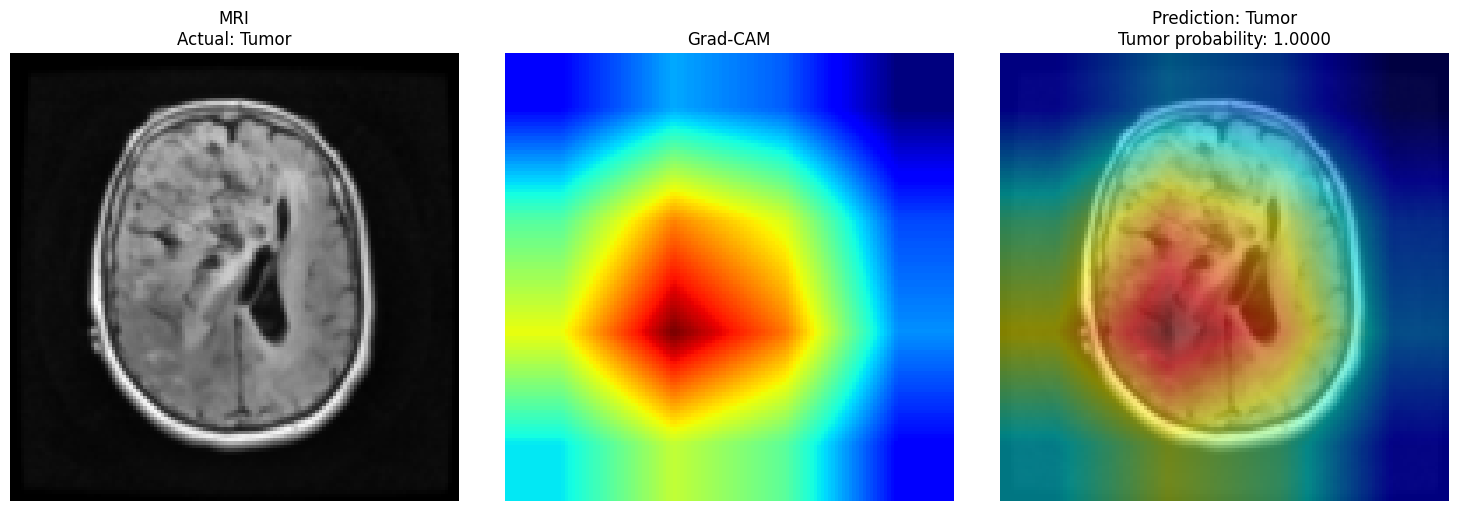

In [33]:
# CELL 33 — Single test-sample Grad-CAM visualization

# Use the held-out test split for the final explainability example.
test_cls_images, test_cls_labels = next(iter(research_test_cls_loader))

sample_image = test_cls_images[0]
sample_label = int(test_cls_labels[0].item())

cam, predicted_class, tumor_probability = generate_gradcam(
    cls_model,
    sample_image
)

mri = tensor_to_display_image(sample_image)
mri_rgb = np.stack([mri, mri, mri], axis=-1)

visualization = show_cam_on_image(
    mri_rgb.astype(np.float32),
    cam,
    use_rgb=True
)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(mri, cmap="gray")
plt.title(
    f"MRI\nActual: {'Tumor' if sample_label else 'No Tumor'}"
)
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(visualization)
plt.title(
    f"Prediction: {'Tumor' if predicted_class else 'No Tumor'}\n"
    f"Tumor probability: {tumor_probability:.4f}"
)
plt.axis("off")

plt.tight_layout()
plt.show()


In [34]:
# CELL 34 — Grad-CAM vs ground-truth tumor-mask overlap

def calculate_gradcam_overlap(cam, mask, threshold=0.5):
    cam_binary = cam >= threshold
    mask_binary = mask >= 0.5

    intersection = np.logical_and(
        cam_binary, mask_binary
    ).sum()

    union = np.logical_or(
        cam_binary, mask_binary
    ).sum()

    cam_iou = intersection / (union + 1e-8)

    if mask_binary.sum() == 0:
        tumor_coverage = 0.0
    else:
        tumor_coverage = intersection / (mask_binary.sum() + 1e-8)

    return float(cam_iou), float(tumor_coverage)


# The test segmentation and classification loaders are built from the same test_df,
# so their sample ordering corresponds to the held-out test split.
test_seg_images, test_seg_masks = next(iter(research_test_loader))

gradcam_ious = []
gradcam_coverages = []

N_GRADCAM = min(20, len(test_seg_images))

for i in range(N_GRADCAM):
    cam_i, _, _ = generate_gradcam(
        cls_model,
        test_seg_images[i]
    )

    mask_i = test_seg_masks[i, 0].numpy()
    cam_iou, coverage = calculate_gradcam_overlap(
        cam_i,
        mask_i
    )

    gradcam_ious.append(cam_iou)
    gradcam_coverages.append(coverage)

mean_gradcam_iou = float(np.mean(gradcam_ious)) if gradcam_ious else 0.0
mean_tumor_coverage = float(np.mean(gradcam_coverages)) if gradcam_coverages else 0.0

print("Number of test samples analyzed:", N_GRADCAM)
print(f"Mean Grad-CAM IoU: {mean_gradcam_iou:.6f}")
print(f"Mean Tumor Coverage: {mean_tumor_coverage:.6f}")


Number of test samples analyzed: 16
Mean Grad-CAM IoU: 0.031897
Mean Tumor Coverage: 0.362819


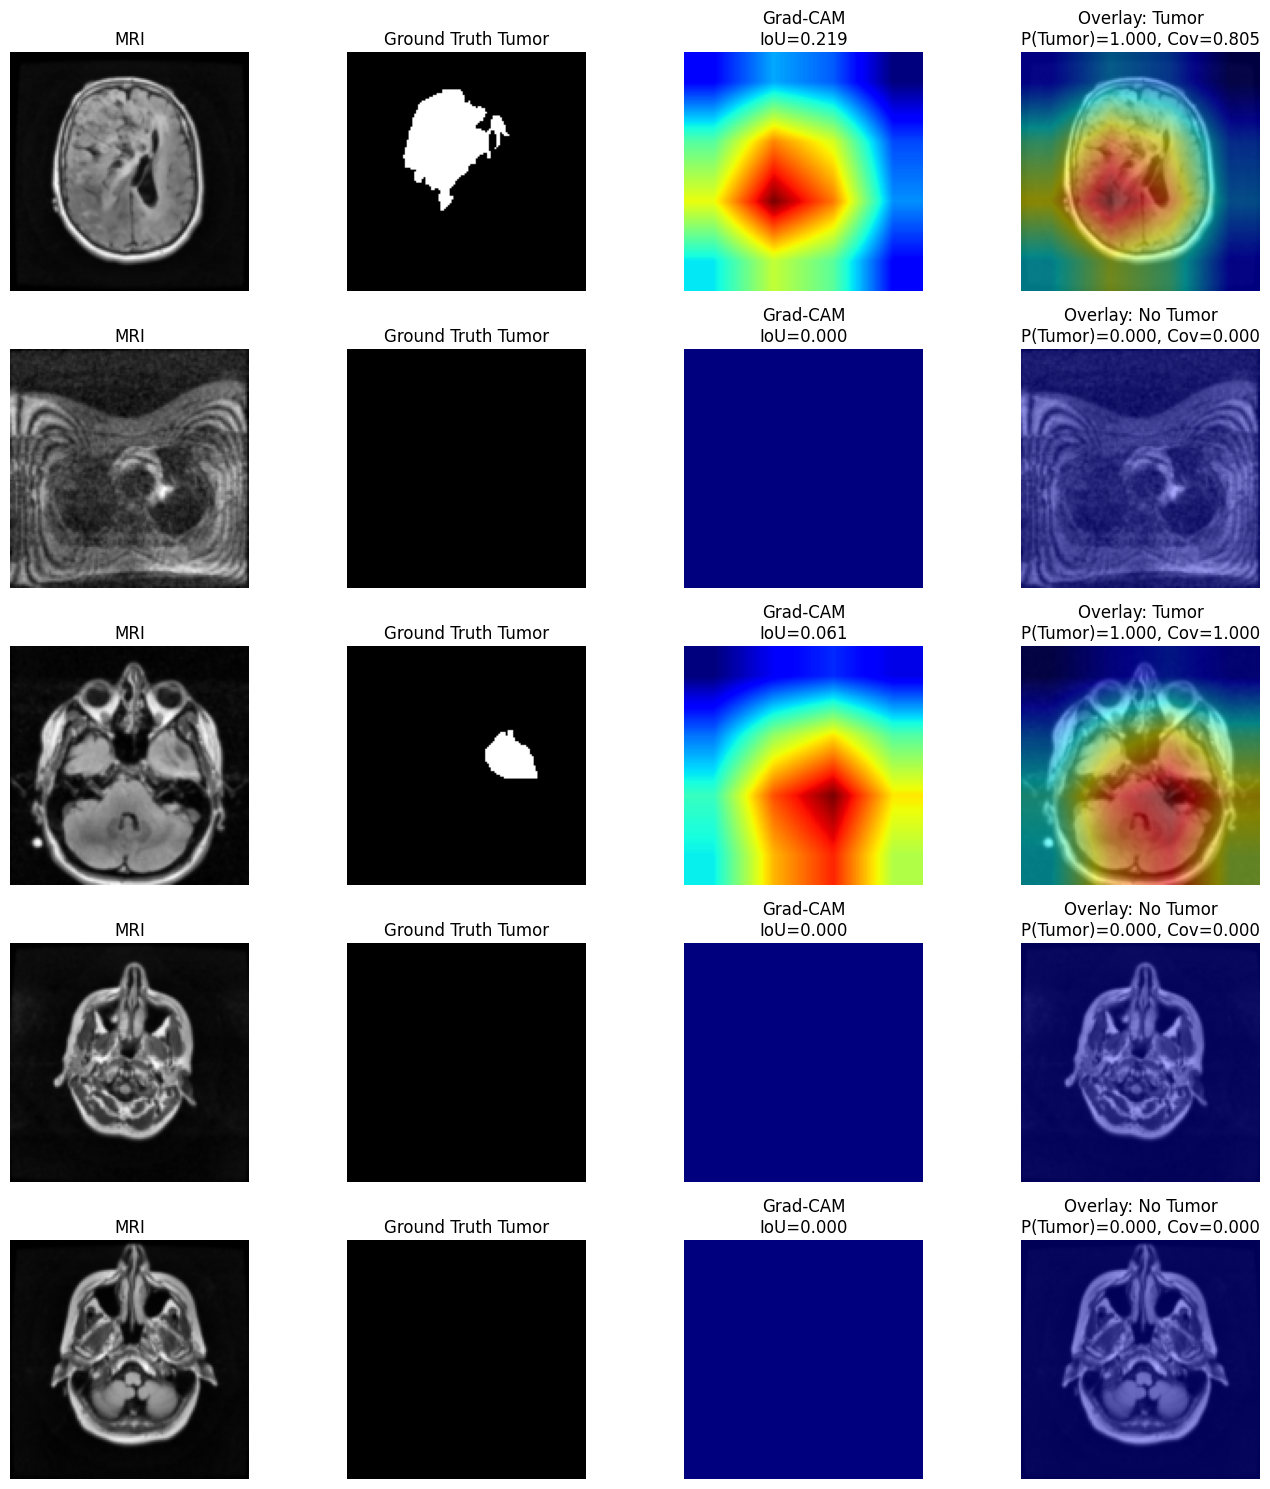

In [35]:
# CELL 35 — Grad-CAM + ground-truth visualization for multiple test samples

N = min(5, len(test_seg_images))
fig, axes = plt.subplots(
    N, 4,
    figsize=(14, 3 * N),
    squeeze=False
)

for i in range(N):
    image = test_seg_images[i]
    mask = test_seg_masks[i, 0].numpy()

    cam_i, predicted_class_i, probability_i = generate_gradcam(
        cls_model,
        image
    )

    mri_i = tensor_to_display_image(image)
    mri_rgb_i = np.stack([mri_i, mri_i, mri_i], axis=-1)
    overlay_i = show_cam_on_image(
        mri_rgb_i.astype(np.float32),
        cam_i,
        use_rgb=True
    )

    cam_iou, coverage_i = calculate_gradcam_overlap(cam_i, mask)

    axes[i, 0].imshow(mri_i, cmap="gray")
    axes[i, 0].set_title("MRI")
    axes[i, 0].axis("off")

    axes[i, 1].imshow(mask, cmap="gray")
    axes[i, 1].set_title("Ground Truth Tumor")
    axes[i, 1].axis("off")

    axes[i, 2].imshow(cam_i, cmap="jet")
    axes[i, 2].set_title(
        f"Grad-CAM\nIoU={cam_iou:.3f}"
    )
    axes[i, 2].axis("off")

    axes[i, 3].imshow(overlay_i)
    axes[i, 3].set_title(
        f"Overlay: {'Tumor' if predicted_class_i else 'No Tumor'}\n"
        f"P(Tumor)={probability_i:.3f}, Cov={coverage_i:.3f}"
    )
    axes[i, 3].axis("off")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "test_gradcam_ground_truth_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


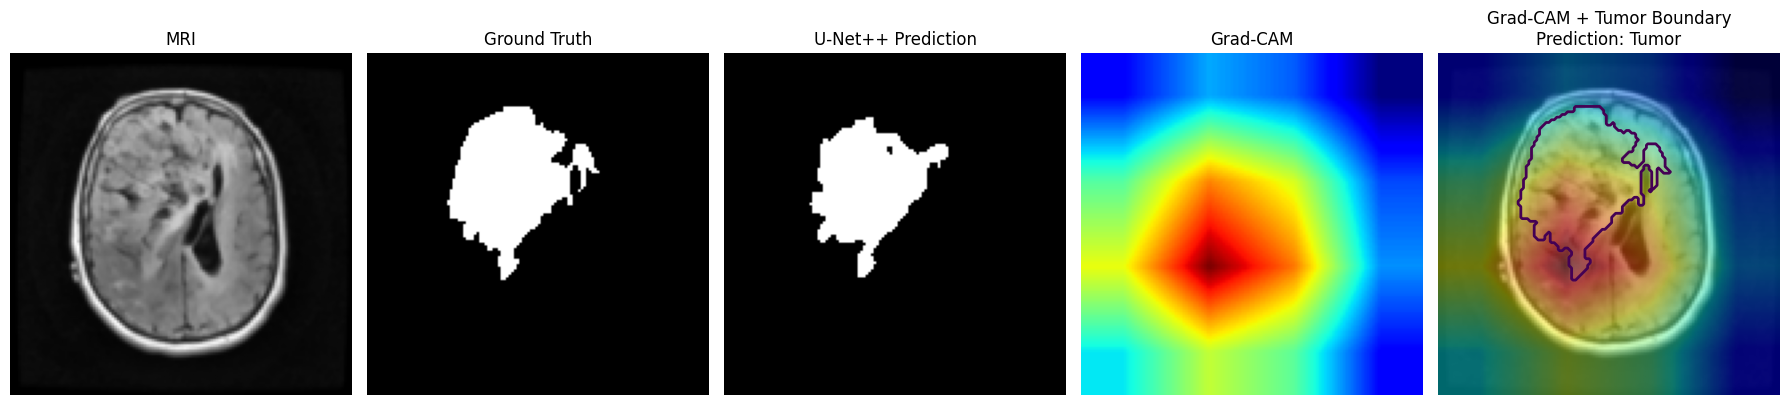

In [36]:
# CELL 36 — Combined U-Net++ + Grad-CAM visualization

# Use the first held-out test sample.
image = test_seg_images[0]
true_mask = test_seg_masks[0, 0].numpy()

# U-Net++ prediction
seg_model.eval()
with torch.no_grad():
    segmentation_logits = seg_model(
        image.unsqueeze(0).to(DEVICE)
    )

segmentation_probability = torch.sigmoid(
    segmentation_logits
)[0, 0].cpu().numpy()

segmentation_prediction = (
    segmentation_probability >= 0.5
)

# Classifier Grad-CAM
cam, predicted_class, tumor_probability = generate_gradcam(
    cls_model,
    image
)

mri = image[0].numpy()

plt.figure(figsize=(18, 4))

plt.subplot(1, 5, 1)
plt.imshow(mri, cmap="gray")
plt.title("MRI")
plt.axis("off")

plt.subplot(1, 5, 2)
plt.imshow(true_mask, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1, 5, 3)
plt.imshow(segmentation_prediction, cmap="gray")
plt.title("U-Net++ Prediction")
plt.axis("off")

plt.subplot(1, 5, 4)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM")
plt.axis("off")

plt.subplot(1, 5, 5)
plt.imshow(mri, cmap="gray")
plt.imshow(cam, cmap="jet", alpha=0.45)
plt.contour(
    true_mask,
    levels=[0.5],
    linewidths=2
)
plt.title(
    f"Grad-CAM + Tumor Boundary\n"
    f"Prediction: {'Tumor' if predicted_class else 'No Tumor'}"
)
plt.axis("off")

plt.tight_layout()
plt.savefig(
    FIG_DIR / "combined_segmentation_gradcam.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [37]:
# CELL 37 — Full held-out test classification report

print("=" * 70)
print("CLASSIFICATION REPORT — HELD-OUT TEST SET")
print("=" * 70)

print(
    classification_report(
        test_cls["labels"],
        test_cls["predictions"],
        target_names=["No Tumor", "Tumor"],
        zero_division=0
    )
)


CLASSIFICATION REPORT — HELD-OUT TEST SET
              precision    recall  f1-score   support

    No Tumor       0.96      0.93      0.95       384
       Tumor       0.88      0.93      0.91       206

    accuracy                           0.93       590
   macro avg       0.92      0.93      0.93       590
weighted avg       0.93      0.93      0.93       590



In [39]:
# CELL 38 — Explainability summary and final research results

explainability_results = pd.DataFrame({
    "Metric": [
        "Mean Grad-CAM IoU",
        "Mean Grad-CAM Tumor Coverage"
    ],
    "Score": [
        mean_gradcam_iou,
        mean_tumor_coverage
    ],
    "Evaluation": [
        "Held-out test subset",
        "Held-out test subset"
    ]
})

explainability_results.to_csv(
    RESEARCH_DIR / "gradcam_explainability_metrics.csv",
    index=False
)

print("=" * 70)
print("FINAL BRAIN TUMOR AI PIPELINE RESULTS")
print("=" * 70)

print("\nSEGMENTATION — U-NET++ (HELD-OUT TEST)")
print("-" * 50)
for key, value in test_seg_metrics.items():
    print(f"{key:28s}: {value:.6f}")

print("\nCLASSIFICATION — RESNET18 (HELD-OUT TEST)")
print("-" * 50)
for key in ["accuracy", "precision", "recall", "f1", "auc", "ap"]:
    if key in test_cls and np.isfinite(test_cls[key]):
        print(f"{key.upper():28s}: {test_cls[key]:.6f}")

print("\nEXPLAINABILITY")
print("-" * 50)
print(f"Mean Grad-CAM IoU       : {mean_gradcam_iou:.6f}")
print(f"Mean Tumor Coverage     : {mean_tumor_coverage:.6f}")

print("\nSaved explainability metrics to:")
print(RESEARCH_DIR / "gradcam_explainability_metrics.csv")


FINAL BRAIN TUMOR AI PIPELINE RESULTS

SEGMENTATION — U-NET++ (HELD-OUT TEST)
--------------------------------------------------
pixel_accuracy              : 0.996705
pixel_precision             : 0.841024
pixel_recall                : 0.841836
pixel_specificity           : 0.998330
pixel_dice                  : 0.841430
pixel_iou                   : 0.726266
mean_case_dice              : 0.824069
median_case_dice            : 1.000000
mean_case_iou               : 0.790648
median_case_iou             : 1.000000
mean_case_precision         : 0.832210
median_case_precision       : 1.000000
mean_case_recall            : 0.832326
median_case_recall          : 1.000000

CLASSIFICATION — RESNET18 (HELD-OUT TEST)
--------------------------------------------------
ACCURACY                    : 0.932203
PRECISION                   : 0.884259
RECALL                      : 0.927184
F1                          : 0.905213
AUC                         : 0.970779
AP                          : 0.9679

In [40]:
import shutil

shutil.make_archive(
    "/kaggle/working/all_outputs",
    "zip",
    "/kaggle/working"
)

'/kaggle/working/all_outputs.zip'